## 1. Spark и библиотеки

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession, Window, functions as F
from pyspark.ml.recommendation import ALS
from pyspark.ml.evaluation import RegressionEvaluator

spark = (SparkSession.builder.master("local[6]").appName("book-recommendations")
         .config("spark.sql.shuffle.partitions", "12").getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

## 2. Чтение данных

In [2]:
ratings = (spark.read.csv("data/Ratings.csv", header=True, schema="`User-ID` int, ISBN string, `Book-Rating` double")
           .select(F.col("User-ID").alias("user_id"), F.upper(F.trim("ISBN")).alias("isbn"), F.col("Book-Rating").alias("rating")))
books = (spark.read.option("multiLine", True).option("escape", '"').csv("data/Books.csv", header=True)
         .select(F.upper(F.trim("ISBN")).alias("isbn"), F.col("Book-Title").alias("title"),
                 F.col("Book-Author").alias("author"), F.col("Publisher").alias("publisher")).dropDuplicates(["isbn"]))
users = spark.read.option("multiLine", True).option("escape", '"').csv("data/Users.csv", header=True, schema="`User-ID` int, Location string, Age double")
display(pd.DataFrame([(name, frame.count()) for name, frame in [("ratings", ratings), ("books", books), ("users", users)]], columns=["table", "rows"]))
ratings.show(5)
books.show(5, truncate=50)

,table,rows
0,ratings,1149780
1,books,271046
2,users,278858


+-------+----------+------+
|user_id|      isbn|rating|
+-------+----------+------+
| 276725|034545104X|   0.0|
| 276726|0155061224|   5.0|
| 276727|0446520802|   0.0|
| 276729|052165615X|   3.0|
| 276729|0521795028|   6.0|
+-------+----------+------+
only showing top 5 rows



+----------+--------------------------------------------------+-----------------------------+---------------------------+
|      isbn|                                             title|                       author|                  publisher|
+----------+--------------------------------------------------+-----------------------------+---------------------------+
|0000913154|The Way Things Work: An Illustrated Encyclopedi...|C. van Amerongen (translator)|       Simon &amp; Schuster|
|0001047663|                                  Matter Of Honour|               Jeffrey Archer|     Trafalgar Square Books|
|0001047973|                                   Brave New World|                Aldous Huxley|Trafalgar Square Publishing|
|0001056107|            Farmer Giles of Ham: And Other Stories|             J. R. R. Tolkien|           Trafalgar Square|
|0001232088|                         Paddington in the Kitchen|                 Michael Bond|   HarperCollins Publishers|
+----------+------------

## 3. Оценки и активность пользователей

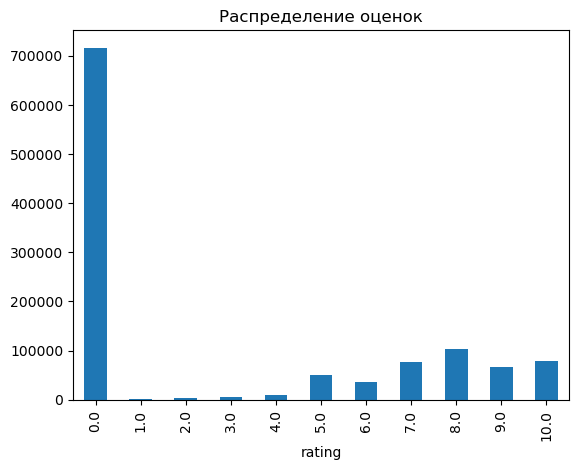

+-------+-----+
|user_id|count|
+-------+-----+
|  11676|13602|
| 198711| 7550|
| 153662| 6109|
|  98391| 5891|
|  35859| 5850|
| 212898| 4785|
| 278418| 4533|
|  76352| 3367|
| 110973| 3100|
| 235105| 3067|
+-------+-----+
only showing top 10 rows



повторов пар: 0


взаимодействий без описания книги: 118641


+----------------------+
|missing_or_unusual_age|
+----------------------+
|                112010|
+----------------------+



In [3]:
distribution = ratings.groupBy("rating").count().orderBy("rating").toPandas()
distribution.plot.bar(x="rating", y="count", legend=False, title="Распределение оценок")
plt.show()
ratings.groupBy("user_id").count().orderBy(F.desc("count")).show(10)
print("повторов пар:", ratings.count() - ratings.dropDuplicates(["user_id", "isbn"]).count())
print("взаимодействий без описания книги:", ratings.join(books, "isbn", "left_anti").count())
users.select(F.sum((F.col("Age").isNull() | ~F.col("Age").between(5, 100)).cast("int")).alias("missing_or_unusual_age")).show()

## 4. Подготовка и разделение данных

In [4]:
pairs = (ratings.filter(F.col("user_id").isNotNull() & F.col("isbn").isNotNull() & F.col("rating").between(0, 10))
         .groupBy("user_id", "isbn").agg(F.avg(F.when(F.col("rating") > 0, F.col("rating"))).alias("rating")))
catalog = (pairs.select("isbn").union(books.select("isbn")).distinct()
           .withColumn("book_id", (F.row_number().over(Window.orderBy("isbn")) - 1).cast("int"))).cache()
interactions = pairs.join(catalog, "isbn").cache()
interactions.count()
train_history, valid_history, test_history = [frame.cache() for frame in interactions.randomSplit([.8, .1, .1], seed=42)]
train, valid, test = [frame.filter(F.col("rating").isNotNull()).cache() for frame in [train_history, valid_history, test_history]]
display(pd.DataFrame([(name, frame.count()) for name, frame in [("train", train), ("validation", valid), ("test", test)]], columns=["split", "explicit_ratings"]))

,split,explicit_ratings
0,train,346931
1,validation,43201
2,test,43539


## 5. Топ-10 популярных книг

In [5]:
popular = (train_history.groupBy("book_id", "isbn").agg(F.countDistinct("user_id").alias("readers"))
           .orderBy(F.desc("readers"), "isbn").cache())
display(popular.limit(10).join(books, "isbn", "left").orderBy(F.desc("readers"), "isbn").toPandas())

,isbn,book_id,readers,title,author,publisher
0,0971880107,247880,1988,Wild Animus,Rich Shapero,Too Far
1,0316666343,47452,1038,The Lovely Bones: A Novel,Alice Sebold,"Little, Brown"
2,0385504209,83496,699,The Da Vinci Code,Dan Brown,Doubleday
3,0060928336,9641,592,Divine Secrets of the Ya-Ya Sisterhood: A Novel,Rebecca Wells,Perennial
4,0312195516,41061,592,The Red Tent (Bestselling Backlist),Anita Diamant,Picador USA
5,0679781587,166915,523,None,None,None
6,0142001740,28169,501,The Secret Life of Bees,Sue Monk Kidd,Penguin Books
7,044023722X,101810,501,A Painted House,John Grisham,Dell Publishing Company
8,067976402X,166645,495,Snow Falling on Cedars,David Guterson,Vintage Books USA
9,059035342X,144315,476,Harry Potter and the Sorcerer's Stone (Harry P...,J. K. Rowling,Arthur A. Levine Books


## 6. Три ближайших пользователя

In [6]:
target_user = train.groupBy("user_id").count().orderBy(F.desc("count"), "user_id").first().user_id
target_ratings = train.filter(F.col("user_id") == target_user).select("book_id", F.col("rating").alias("target_rating"))
neighbors = (train.filter(F.col("user_id") != target_user).join(target_ratings, "book_id")
             .groupBy("user_id").agg(F.count("*").alias("common_books"), F.avg(F.abs(F.col("rating") - F.col("target_rating"))).alias("mae"))
             .filter(F.col("common_books") >= 5)
             .withColumn("similarity", F.col("common_books") / (F.col("common_books") + 10) * (1 - F.col("mae") / 9))
             .orderBy(F.desc("similarity"), "user_id").limit(3).cache())
print("пользователь:", target_user)
neighbors.show()

пользователь: 11676


+-------+------------+------------------+------------------+
|user_id|common_books|               mae|        similarity|
+-------+------------+------------------+------------------+
|  98391|         171| 1.719298245614035|0.7642725598526704|
|  95359|          93|1.7526881720430108|0.7270765911542612|
|  16795|         112|1.9107142857142858|0.7231329690346083|
+-------+------------+------------------+------------------+



## 7. Книги от единомышленников

In [7]:
seen = train_history.filter(F.col("user_id") == target_user).select("book_id")
neighbor_recommendations = (train.join(neighbors.select("user_id", "similarity"), "user_id")
                           .filter(F.col("rating") >= 8).join(seen, "book_id", "left_anti")
                           .groupBy("book_id", "isbn").agg((F.sum(F.col("rating") * F.col("similarity")) / F.sum("similarity")).alias("score"), F.count("*").alias("votes"))
                           .join(books, "isbn", "left").orderBy(F.desc("votes"), F.desc("score"), "isbn"))
display(neighbor_recommendations.limit(10).toPandas())

,isbn,book_id,score,votes,title,author,publisher
0,0316666343,47452,9.498640,2,The Lovely Bones: A Novel,Alice Sebold,"Little, Brown"
1,0345438329,56896,9.000000,2,Big Stone Gap: A Novel (Ballantine Reader's Ci...,Adriana Trigiani,Ballantine Books
2,055358412X,139789,9.000000,2,Beach Roses,Jean Stone,Bantam Books
3,0553801376,139980,9.000000,2,One Door Away from Heaven,Dean R. Koontz,Bantam Books
4,0140179836,22635,8.997281,2,The Liar's Club: A Memoir,Mary Karr,Penguin USA (Paper)
5,0316168688,46760,8.972341,2,The Dogs of Babel (Today Show Book Club #12),Carolyn Parkhurst,"Little, Brown"
6,0553107305,131560,8.513829,2,Chopping Spree,DIANE MOTT DAVIDSON,Bantam
7,155166884X,250998,8.513829,2,Doing Good,Pamela Morsi,Mira Books
8,0345445724,57132,8.486171,2,Entering Normal,Anne D. Leclaire,Ballantine Books
9,0505525046,123018,8.000000,2,A Stranger's Desire,Kimberly Raye,Dorchester Publishing Company


## 8. Базовая ALS

In [8]:
evaluator = RegressionEvaluator(labelCol="rating", predictionCol="prediction", metricName="rmse")

def evaluate(model, frame, name):
    predictions = model.transform(frame).cache()
    known = predictions.filter(~F.isnan("prediction") & F.col("prediction").isNotNull())
    result = dict(model=name, rmse=evaluator.evaluate(known), coverage=known.count() / frame.count())
    predictions.unpersist()
    return result

als = ALS(userCol="user_id", itemCol="book_id", ratingCol="rating", rank=10, regParam=.1,
          maxIter=10, seed=42, coldStartStrategy="nan")
baseline_model = als.fit(train)
baseline_result = evaluate(baseline_model, valid, "rank=10, reg=0.1")
display(pd.DataFrame([baseline_result]))

,model,rmse,coverage
0,"rank=10, reg=0.1",3.753612,0.589824


## 9. Усиление регуляризации

In [9]:
regularized_model = als.copy({als.regParam: .3}).fit(train)
regularized_result = evaluate(regularized_model, valid, "rank=10, reg=0.3")
display(pd.DataFrame([baseline_result, regularized_result]))

,model,rmse,coverage
0,"rank=10, reg=0.1",3.753612,0.589824
1,"rank=10, reg=0.3",2.996581,0.589824


## 10. Увеличение ранга

In [10]:
larger_model = als.copy({als.rank: 20, als.regParam: .3}).fit(train)
larger_result = evaluate(larger_model, valid, "rank=20, reg=0.3")
display(pd.DataFrame([baseline_result, regularized_result, larger_result]))

,model,rmse,coverage
0,"rank=10, reg=0.1",3.753612,0.589824
1,"rank=10, reg=0.3",2.996581,0.589824
2,"rank=20, reg=0.3",2.932446,0.589824


## 11. Итоговая тестовая оценка

In [11]:
experiments = [(baseline_model, baseline_result), (regularized_model, regularized_result), (larger_model, larger_result)]
best_model, best_valid = min(experiments, key=lambda pair: pair[1]["rmse"])
test_result = evaluate(best_model, test, best_valid["model"])
display(pd.DataFrame([test_result]))
test_predictions = best_model.transform(test)
known_test = test_predictions.filter(~F.isnan("prediction"))
mean_rating = train.agg(F.avg("rating")).first()[0]
print("rmse среднего на тех же известных парах:", evaluator.evaluate(known_test.withColumn("prediction", F.lit(mean_rating))))
display(known_test.join(books, "isbn", "left").select("user_id", "title", "rating", "prediction").limit(10).toPandas())

,model,rmse,coverage
0,"rank=20, reg=0.3",2.959346,0.592067


rmse среднего на тех же известных парах: 1.8064141149004256


,user_id,title,rating,prediction
0,141901,None,9.0,7.829088
1,216882,None,5.0,6.084419
2,109955,Just Williams: An Autobiography,10.0,8.156734
3,235805,None,4.0,4.443590
4,212631,Distant Voices,6.0,-0.555772
5,251076,WHISPERS OF BETRAYAL,6.0,1.025249
6,137190,None,7.0,5.930669
7,56360,None,9.0,0.475530
8,189848,None,8.0,2.588826
9,252827,None,10.0,3.083532


## 12. Холодный пользователь, холодная книга и одна оценка

In [12]:
cold_user = 2147483647
known_book = best_model.itemFactors.select(F.col("id").alias("book_id")).orderBy("book_id").first().book_id
cold_book = catalog.join(best_model.itemFactors, catalog.book_id == best_model.itemFactors.id, "left_anti").first().book_id
one_rating_user = train.groupBy("user_id").count().filter("count = 1").orderBy("user_id").first().user_id
cases = spark.createDataFrame([(cold_user, known_book, "новый пользователь"),
                               (target_user, cold_book, "новая книга"),
                               (one_rating_user, known_book, "одна оценка в train")], "user_id int, book_id int, case string")
best_model.transform(cases).show(truncate=False)

+----------+-------+-------------------+----------+
|user_id   |book_id|case               |prediction|
+----------+-------+-------------------+----------+
|11676     |25     |новая книга        |NaN       |
|2147483647|1      |новый пользователь |NaN       |
|9         |1      |одна оценка в train|0.49512178|
+----------+-------+-------------------+----------+



## 13. Гибридные рекомендации

In [13]:
def recommend_books(user_id, k=3):
    user_seen = train_history.filter(F.col("user_id") == user_id).select("book_id")
    if best_model.userFactors.filter(F.col("id") == user_id).count():
        candidates = catalog.join(books.select("isbn"), "isbn").join(user_seen, "book_id", "left_anti").withColumn("user_id", F.lit(user_id).cast("int"))
        recommendations = (best_model.transform(candidates).filter(~F.isnan("prediction"))
                           .withColumnRenamed("prediction", "score").withColumn("source", F.lit("ALS")))
    else:
        recommendations = (popular.join(user_seen, "book_id", "left_anti")
                           .withColumnRenamed("readers", "score").withColumn("source", F.lit("popular")))
    return (recommendations.orderBy(F.desc("score"), "isbn").limit(k).join(books, "isbn", "left")
            .select("isbn", "title", "author", "score", "source").orderBy(F.desc("score"), "isbn"))

display(recommend_books(target_user).toPandas())
display(recommend_books(cold_user).toPandas())
display(recommend_books(one_rating_user).toPandas())

,isbn,title,author,score,source
0,0914615033,Threads of the covenant: Growing up Jewish in ...,Harley L Sachs,9.846443,ALS
1,0918752124,Irma Quarterdeck Reports,Harley L. Sachs,9.846443,ALS
2,0140104321,Cadillac desert: The American West and its dis...,Marc Reisner,9.841674,ALS


,isbn,title,author,score,source
0,0971880107,Wild Animus,Rich Shapero,1988,popular
1,0316666343,The Lovely Bones: A Novel,Alice Sebold,1038,popular
2,0385504209,The Da Vinci Code,Dan Brown,699,popular


,isbn,title,author,score,source
0,055327094X,Qb VII,Leon Uris,6.626882,ALS
1,0679454330,"The Global Soul : Jet Lag, Shopping Malls, and...",PICO IYER,6.061903,ALS
2,1891620614,The Global Me: New Cosmopolitans and the Compe...,G. Pascal Zachary,6.061903,ALS


## 14. Рекомендации по автору и издателю для нового пользователя

In [14]:
liked = books.filter(F.col("isbn") == "0316666343").first()
print("новому пользователю понравилась книга:", liked.title)
content = (catalog.join(books, "isbn").filter(F.col("isbn") != liked.isbn)
           .withColumn("score", F.when(F.col("author") == liked.author, 2).otherwise(0)
                       + F.when(F.col("publisher") == liked.publisher, 1).otherwise(0))
           .filter(F.col("score") > 0)
           .join(best_model.itemFactors.select(F.col("id").alias("book_id"), F.lit(True).alias("has_als_factor")), "book_id", "left")
           .fillna(False, subset=["has_als_factor"]))
display(content.orderBy(F.desc("score"), "isbn").select("title", "author", "publisher", "score", "has_als_factor").limit(3).toPandas())
display(content.filter(~F.col("has_als_factor")).orderBy(F.desc("score"), "isbn")
        .select("title", "author", "publisher", "score", "has_als_factor").limit(3).toPandas())

новому пользователю понравилась книга: The Lovely Bones: A Novel


,title,author,publisher,score,has_als_factor
0,Lucky : A Memoir,Alice Sebold,Back Bay Books,2,True
1,The Lovely Bones,Alice Sebold,Back Bay Books,2,True
2,Lucky,Alice Sebold,Scribner,2,True


,title,author,publisher,score,has_als_factor
0,Lucky,Alice Sebold,Scribner,2,False
1,The Lovely Bones,Alice Sebold,Recorded Books,2,False
2,The Lovely Bones (Reader's Companion),Alice Sebold,Barnes &amp; Noble Books-Imports,2,False


## 15. Завершение

In [15]:
spark.stop()